Extract profiles at Faroe Shetland Channel for 1950-1969 and 1995-2014.  I already did this for Denmark Strait in the Code Nordic_Seas_v3.py but I want to create a clean version here.

In [6]:
import matplotlib.pyplot as plt
import intake
import dask
import intake
import numpy as np
import xarray as xr
import cf_xarray as cfxr
import pickle
from pathlib import Path

In [8]:
# Load model output already extractedin Nordic_Seas_V3 using:
from pathlib import Path
save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/dset_dict.pkl')

with open(save_path, 'rb') as f:
    dset_dict = pickle.load(f)

In [10]:
#Set location and repeat for each location
# Define locations (in lon 0-360 convention)
locations = {'FSChannel': {'lat': 64, 'lon': 356} }   

# 'DenStrait': {'lat': 67.5, 'lon': 334},
    
location =  'FSChannel'

In [12]:
def extract_profiles(dset_dict, period_name, time_slice):
    """
    Extract temperature and salinity profiles for a specific time period.
    Uses optimized bounding box search with Haversine distance.
    """
    
    profiles = {}
    #use a search window to speed things up
    search_lat_window = 3  # degrees
    search_lon_window = 3  # degrees
    
    for model_idx, (key, ds) in enumerate(dset_dict.items()):
        model_name = key.split(".")[2]
        print(f"\nProcessing {model_name} ({period_name})...")
        
        profiles[model_name] = {}
        
        try:
            # Select time period using index slicing
            n_times = ds.dims['time']
            print(f"  Total time steps: {n_times}")
            
            ds_period = ds.isel(time=time_slice)
            n_selected = ds_period.dims['time']
            print(f"  Selected time steps: {n_selected}")
            
            # Get lat/lon arrays
            lat_2d = ds['lat'].values
            lon_2d = ds['lon'].values
            
            # Get data dimensions
            data_y_size = ds.dims['y']
            data_x_size = ds.dims['x']
            
            print(f"  Lat/lon grid shape: {lat_2d.shape}")
            print(f"  Data dimensions: y={data_y_size}, x={data_x_size}")
            
            # Ensure lat/lon shape matches data dimensions (y, x)
            if lat_2d.shape != (data_y_size, data_x_size):
                print(f"   Transposing lat/lon to match data dimensions")
                lat_2d = lat_2d.T
                lon_2d = lon_2d.T
                print(f"   New lat/lon shape: {lat_2d.shape}")
            
            # Extract data for each location with optimized search
            for loc_name, coords in locations.items():
                try:
                    print(f"  {loc_name}: target ({coords['lat']:.1f}°N, {coords['lon']:.1f}°E)")
                    
                    # === OPTIMIZED: Bounding box pre-filter ===
                    lat_mask = np.abs(lat_2d - coords['lat']) <= search_lat_window
                    lon_mask = np.abs(lon_2d - coords['lon']) <= search_lon_window
                    search_region = lat_mask & lon_mask
                    
                    # Get indices of cells in search region
                    search_indices = np.where(search_region)
                    
                    if len(search_indices[0]) == 0:
                        print(f"    ⚠️ No grid points found within {search_lat_window}° of target")
                        continue
                    
                    # === OPTIMIZED: Haversine distance only for search region ===
                    lat_search = lat_2d[search_region]
                    lon_search = lon_2d[search_region]
                    
                    # Convert to radians
                    target_lat_rad = np.radians(coords['lat'])
                    target_lon_rad = np.radians(coords['lon'])
                    lat_search_rad = np.radians(lat_search)
                    lon_search_rad = np.radians(lon_search)
                    
                    # Haversine formula
                    dlat = lat_search_rad - target_lat_rad
                    dlon = lon_search_rad - target_lon_rad
                    a = (np.sin(dlat/2)**2 + 
                         np.cos(target_lat_rad) * np.cos(lat_search_rad) * np.sin(dlon/2)**2)
                    dist_search = 2 * np.arcsin(np.sqrt(a))
                    
                    # Find nearest within search region
                    nearest_idx = np.argmin(dist_search)
                    row_id = search_indices[0][nearest_idx]
                    column_id = search_indices[1][nearest_idx]
                    
                    # Get actual coordinates at this grid point
                    actual_lat = lat_2d[row_id, column_id]
                    actual_lon = lon_2d[row_id, column_id]
                    
                    print(f"           → found ({actual_lat:.2f}°N, {actual_lon:.2f}°E)")
                    print(f"           → grid indices: row={row_id}, col={column_id}")
                    
                    loc_data = {}
                    
                    # Extract profiles for both variables
                    for var in ['thetao', 'so']:
                        if var not in ds_period:
                            print(f"    {var}: not available")
                            continue
                        
                        # Extract and compute only this point's data
                        profile = (ds_period[var]
                                  .isel(y=row_id, x=column_id)
                                  .compute()
                                  .mean(dim='time')
                                  .squeeze())
                        
                        # Check for valid data
                        n_valid = np.sum(~np.isnan(profile.values))
                        n_total = len(profile.values)
                        
                        loc_data[var] = profile.values
                        print(f"    {var}: extracted ({n_valid}/{n_total} valid depths)")
                    
                    # Get depth coordinate
                    if 'lev_bounds' in ds:
                        depths = ds['lev_bounds'].mean(dim='bnds').values
                    elif 'lev' in ds:
                        depths = ds['lev'].values
                    elif 'rho' in ds:
                        depths = ds['rho'].values
                    else:
                        print(f"    ⚠️ No depth coordinate found")
                        if 'thetao' in loc_data:
                            depths = np.arange(len(loc_data['thetao']))
                        elif 'so' in loc_data:
                            depths = np.arange(len(loc_data['so']))
                        else:
                            continue
                    
                    loc_data['depth'] = depths
                    loc_data['actual_lat'] = actual_lat
                    loc_data['actual_lon'] = actual_lon
                    
                    # Only save if we have at least one variable
                    if 'thetao' in loc_data or 'so' in loc_data:
                        profiles[model_name][loc_name] = loc_data
                        print(f"    ✓ Saved profile")
                    
                except Exception as e:
                    print(f"    ❌ {loc_name} failed: {e}")
                    import traceback
                    traceback.print_exc()
        
        except Exception as e:
            print(f"  ❌ Model failed: {e}")
            import traceback
            traceback.print_exc()
    
    return profiles

In [14]:
import time
print("\n" + "="*60)
print("EXTRACTING LATE PERIOD (1950-1969")
print("="*60)
# Start timing
tic = time.perf_counter()
#profiles_late = extract_profiles(dict(list(dset_dict.items())[:4]), "1995-2014", slice(-240, None)) #first model only
profiles_mid= extract_profiles(dict(list(dset_dict.items())),"1950-1969", slice(1200, 1439))

# Start timing
toc = time.perf_counter()

print(f"\n✓ FSC mid profiles extracted: {len(profiles_late)} models")
print(f"\n✓ Mid profiles extracted in {toc-tic:.2f} seconds")


EXTRACTING LATE PERIOD (1950-1969

Processing CAS-ESM2-0 (1950-1969)...
  Total time steps: 1980
  Selected time steps: 239
  Lat/lon grid shape: (360, 196)
  Data dimensions: y=196, x=360
  → Transposing lat/lon to match data dimensions
  → New lat/lon shape: (196, 360)
  FSChannel: target (64.0°N, 356.0°E)
           → found (64.00°N, 356.00°E)
           → grid indices: row=169, col=356
    thetao: not available
    so: extracted (26/30 valid depths)
    ✓ Saved profile

Processing IPSL-CM6A-LR-INCA (1950-1969)...
  Total time steps: 1980
  Selected time steps: 239
  Lat/lon grid shape: (332, 362)
  Data dimensions: y=332, x=362
  FSChannel: target (64.0°N, 356.0°E)
           → found (64.16°N, 356.13°E)
           → grid indices: row=282, col=279
    thetao: extracted (61/75 valid depths)
    so: extracted (61/75 valid depths)
    ✓ Saved profile

Processing CESM2-WACCM-FV2 (1950-1969)...
  Total time steps: 1980
  Selected time steps: 239
  Lat/lon grid shape: (384, 320)
  Data d

NameError: name 'profiles_late' is not defined

In [18]:
# Save model output for use later
from pathlib import Path
save_path = Path('/Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/profiles_mid_FBC_true.pkl')

with open(save_path, 'wb') as f:
    pickle.dump(profiles_mid, f)

print(f"✓ Saved profiles_late to {save_path}")

✓ Saved profiles_late to /Users/jaimepalter/OneDrive - University of Rhode Island/New Ideas/AMOC Lunch Bunch/profiles_mid_FBC_true.pkl


Processing CAS-ESM2-0...
  ❌ CAS-ESM2-0: 'thetao'
Processing IPSL-CM6A-LR-INCA...
  ✓ Plotting IPSL-CM6A-LR-INCA
Processing CESM2-WACCM-FV2...
  ✓ Plotting CESM2-WACCM-FV2
Processing CAMS-CSM1-0...
  ✓ Plotting CAMS-CSM1-0
Processing MPI-ESM1-2-LR...
  ✓ Plotting MPI-ESM1-2-LR
Processing NorESM2-MM...
  ✓ Plotting NorESM2-MM
Processing TaiESM1...
  ✓ Plotting TaiESM1
Processing BCC-CSM2-MR...
  ✓ Plotting BCC-CSM2-MR
Processing IPSL-CM5A2-INCA...
  ✓ Plotting IPSL-CM5A2-INCA
Processing CESM2...
  ✓ Plotting CESM2
Processing GISS-E2-1-G...
  ✓ Plotting GISS-E2-1-G
Processing MRI-ESM2-0...
  ✓ Plotting MRI-ESM2-0
Processing NESM3...
  ✓ Plotting NESM3
Processing CIESM...
  ✓ Plotting CIESM
Processing MPI-ESM1-2-HR...
  ❌ MPI-ESM1-2-HR: 'so'
Processing IPSL-CM6A-LR...
  ✓ Plotting IPSL-CM6A-LR
Processing EC-Earth3-AerChem...
  ✓ Plotting EC-Earth3-AerChem
Processing FGOALS-g3...
  ✓ Plotting FGOALS-g3
Processing CESM2-WACCM...
  ✓ Plotting CESM2-WACCM
Processing EC-Earth3-Veg-LR...
  ✓ Pl

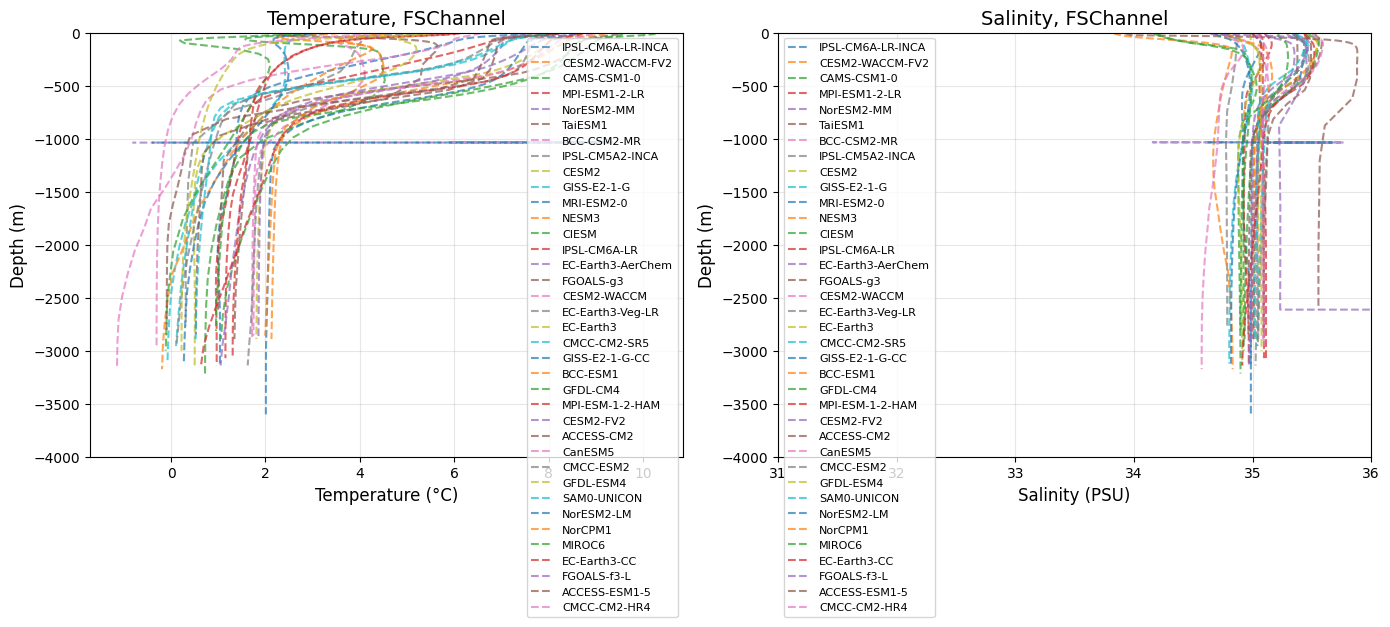

In [22]:
##  Plot to check things worked well
import matplotlib.pyplot as plt
import numpy as np

# Set location
location = 'FSChannel'

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

models_plotted = []

# Plot each model
for model_name, locs in profiles_mid.items():
    print(f"Processing {model_name}...")
    
    if location not in locs:
        print(f"  ⚠️ {location} not in {model_name}")
        continue
    
    data = locs[location]
    
    try:
        # Squeeze arrays
        temp = np.squeeze(data['thetao'])
        sal = np.squeeze(data['so'])
        depth = data['depth']
        
        print(f"  ✓ Plotting {model_name}")
        
        # Temperature
        axes[0].plot(temp, -depth, label=model_name, linewidth=1.5, alpha=0.7, linestyle='--')
    
        # Salinity
        axes[1].plot(sal, -depth, label=model_name, linewidth=1.5, alpha=0.7, linestyle='--')
        
        models_plotted.append(model_name)
    
    except Exception as e:
        print(f"  ❌ {model_name}: {e}")

print(f"\nTotal models plotted: {len(models_plotted)}")
print(f"Models: {models_plotted}")

# Format Temperature plot
axes[0].set_xlabel('Temperature (°C)', fontsize=12)
axes[0].set_ylabel('Depth (m)', fontsize=12)
axes[0].set_ylim(-4000, 0)
axes[0].set_title(f'Temperature, {location}', fontsize=14)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8, loc='best')

# Format Salinity plot
axes[1].set_xlabel('Salinity (PSU)', fontsize=12)
axes[1].set_ylim(-4000, 0)
axes[1].set_xlim(31, 36)
axes[1].set_ylabel('Depth (m)', fontsize=12)
axes[1].set_title(f'Salinity, {location}', fontsize=14)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8, loc='best')

plt.tight_layout()
plt.show()